# The Atalanta model: ten years of accounts, 2016 to 2024/25

Atalanta closed every financial year of the Gasperini era in profit, in a league that loses money as a whole. This notebook rebuilds the numbers behind the paper in `paper/` and the report in `report/` and asks one question: **how much of that profit comes from selling players?**

Data are hand-collected from published accounts (mainly via Calcio e Finanza). Every row in `data/` carries its source. Amounts are in EUR millions.

In [1]:
import sys
from pathlib import Path

import re

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.club_finance import bridge_from_pnl, cagr, retained_earnings_share, trading_share

DATA, FIG = ROOT / "data", ROOT / "figures"
FIG.mkdir(exist_ok=True)

# black and white, same look as the paper. Figures are drawn at the size they are printed in the
# A4 paper (text width 15.8 cm = 6.2 in), so fonts are not scaled; TrueType embedding keeps the PDFs sharp.
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Termes Paper", "TeX Gyre Termes", "Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 400, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "font.size": 8.5, "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "axes.labelsize": 8, "legend.fontsize": 7.5,
})
INK, GREY, LIGHT = "#111111", "#8a8a8a", "#cfcfcf"

def save(fig, name):
    # typographic minus sign in every label (f-strings give a plain hyphen)
    for t in fig.findobj(matplotlib.text.Text):
        t.set_text(re.sub(r"(?<![\w/])-(?=\d)", "\u2212", t.get_text()))
    fig.tight_layout(pad=0.4)
    for ext in ("pdf", "png"):
        fig.savefig(FIG / f"{name}.{ext}", bbox_inches="tight")

periods = pd.read_csv(DATA / "financials_by_period.csv")
periods[["period", "months", "revenue_eur_m", "player_trading_gains_eur_m", "net_profit_eur_m"]]

,period,months,revenue_eur_m,player_trading_gains_eur_m,net_profit_eur_m
0,2016,12,83.1,22.5,0.26
1,2017,12,147.7,46.7,26.70
2,2018,12,155.7,24.2,24.00
3,2019,12,188.6,38.8,26.50
4,2020,12,242.0,68.5,51.70
5,2021,12,242.6,53.6,35.10
6,Jan-Jun 2022,6,119.5,44.2,11.00
7,2022/23,12,193.7,63.2,5.60
8,2023/24,12,243.7,71.0,11.80
9,2024/25,12,320.8,100.9,37.80


## 1. Revenue and the weight of player trading

Atalanta moved its year end from 31 December to 30 June in 2022, so there is a six-month period (Jan to Jun 2022). I keep it in the totals but flag it in the charts.

In [2]:
p = periods.copy()
p["other_revenue"] = p["revenue_eur_m"] - p["player_trading_gains_eur_m"]
p["trading_share"] = trading_share(p["revenue_eur_m"], p["player_trading_gains_eur_m"])

tot_rev, tot_gain = p["revenue_eur_m"].sum(), p["player_trading_gains_eur_m"].sum()
growth = cagr(p["revenue_eur_m"].iloc[0], p["revenue_eur_m"].iloc[-1], years=8.5)
print(f"Revenue 2016 to 2024/25: {tot_rev:,.1f}, of which gains on disposals {tot_gain:,.1f} ({tot_gain / tot_rev:.1%})")
print(f"Revenue CAGR 2016 to 2024/25 (8.5 years): {growth:.1%}")
print(f"Trading share range: {p['trading_share'].min():.0%} to {p['trading_share'].max():.0%}")

Revenue 2016 to 2024/25: 1,937.4, of which gains on disposals 533.6 (27.5%)
Revenue CAGR 2016 to 2024/25 (8.5 years): 17.2%
Trading share range: 16% to 37%


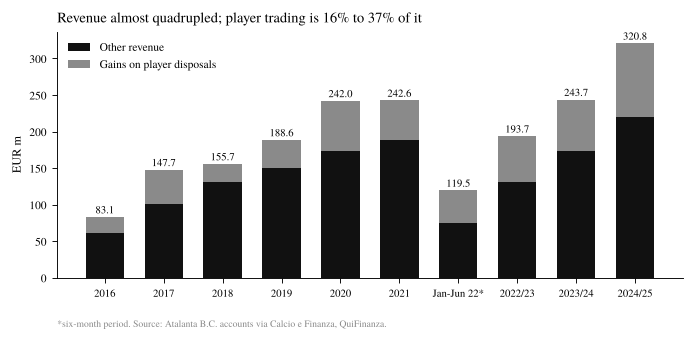

In [3]:
fig, ax = plt.subplots(figsize=(6.2, 3.0))
x = range(len(p))
for i, r in p.iterrows():
    ax.bar(i, r["other_revenue"], color=INK, width=0.65)
    ax.bar(i, r["player_trading_gains_eur_m"], bottom=r["other_revenue"], color=GREY, width=0.65)
    ax.text(i, r["revenue_eur_m"] + 5, f"{r['revenue_eur_m']:.1f}", ha="center", fontsize=7)
ax.set_xticks(list(x), [s.replace("Jan-Jun 2022", "Jan-Jun 22*") for s in p["period"]], fontsize=7)
ax.set_ylabel("EUR m")
ax.legend(["Other revenue", "Gains on player disposals"], frameon=False, loc="upper left")
ax.set_title(f"Revenue almost quadrupled; player trading is {p['trading_share'].min():.0%} to {p['trading_share'].max():.0%} of it", loc="left", fontsize=9.5)
ax.text(0, -0.2, "*six-month period. Source: Atalanta B.C. accounts via Calcio e Finanza, QuiFinanza.",
        transform=ax.transAxes, fontsize=6.3, color=GREY)
save(fig, "fig1_revenue_split")

## 2. Ten profits in a row

Two caveats on the series. For 2022/23 and 2023/24 some sources report EUR 3.8m and 9.8m; I use the figures restated in the following year's accounts (5.6 and 11.8), which is the most recent version. And 2020 to 2021 were Covid years: Atalanta made EUR 86.8m in profit while almost every Serie A club lost money.

Profit 2020 + 2021: 86.8


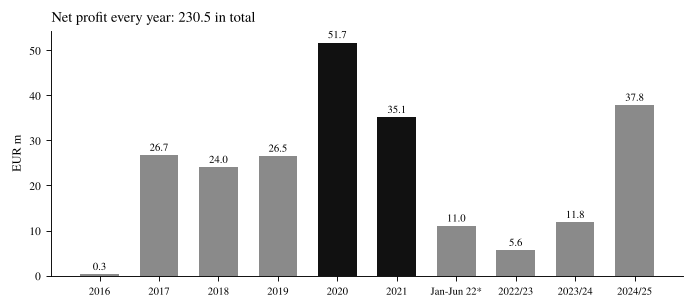

In [4]:
fig, ax = plt.subplots(figsize=(6.2, 2.7))
colors = [INK if per in ("2020", "2021") else GREY for per in p["period"]]
ax.bar(x, p["net_profit_eur_m"], color=colors, width=0.65)
for i, v in enumerate(p["net_profit_eur_m"]):
    ax.text(i, v + 1, f"{v:.1f}", ha="center", fontsize=7)
ax.set_xticks(list(x), [s.replace("Jan-Jun 2022", "Jan-Jun 22*") for s in p["period"]], fontsize=7)
ax.set_ylabel("EUR m")
ax.set_title(f"Net profit every year: {p['net_profit_eur_m'].sum():.1f} in total", loc="left", fontsize=9.5)
save(fig, "fig2_net_profit")
print(f"Profit 2020 + 2021: {p.loc[p['period'].isin(['2020', '2021']), 'net_profit_eur_m'].sum():.1f}")

## 3. The 2024/25 profit bridge: what is left without player sales

In Italian GAAP a gain on a player's registration goes into the value of production, next to TV money and tickets. So EBITDA and EBIT already contain it. The bridge below takes it out. Amortisation of registrations stays, because the squad has to be bought and amortised whether or not anyone is sold.

In [5]:
pnl = pd.read_csv(DATA / "pnl_2024_25.csv")
b = bridge_from_pnl(pnl, "fy_2024_25_eur_m")
b_prev = bridge_from_pnl(pnl, "fy_2023_24_eur_m")
bridge = pd.DataFrame({"2024/25": b.as_series(), "2023/24": b_prev.as_series()}).round(1)
print(f"EBIT without player trading, 2024/25: {b.ebit_ex_trading:.1f}  (2023/24: {b_prev.ebit_ex_trading:.1f})")
bridge

EBIT without player trading, 2024/25: -62.5  (2023/24: -63.6)


,2024/25,2023/24
Structural revenue,199.2,160.1
Operating costs,-185.0,-169.7
EBITDA ex trading,14.2,-9.6
Player trading,121.6,83.7
EBITDA,135.8,74.1
D&A,-76.7,-54.0
EBIT,59.1,20.1
Financial items and tax,-21.3,-8.3
Net profit,37.8,11.8


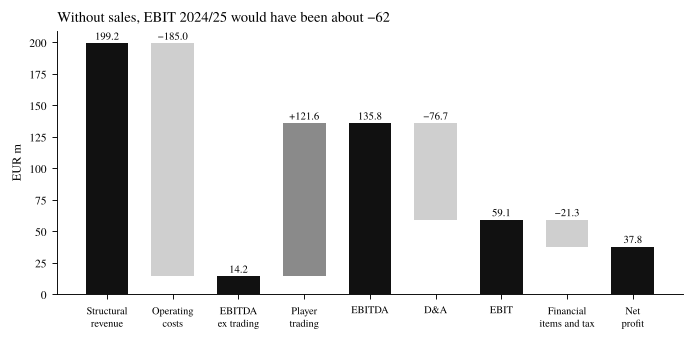

In [6]:
s = b.as_series()
steps = ["Structural revenue", "Operating costs", "EBITDA ex trading", "Player trading", "EBITDA", "D&A", "EBIT",
         "Financial items and tax", "Net profit"]
totals = {"Structural revenue", "EBITDA ex trading", "EBITDA", "EBIT", "Net profit"}
fig, ax = plt.subplots(figsize=(6.2, 3.0))
level = 0
for i, k in enumerate(steps):
    v = s[k]
    if k in totals:
        ax.bar(i, v, color=INK, width=0.65); level = v; top = v
    else:
        bottom = level if v >= 0 else level + v
        ax.bar(i, abs(v), bottom=bottom, color=GREY if v >= 0 else LIGHT, width=0.65)
        level += v; top = max(level, level - v)
    ax.text(i, top + 3, f"{v:+.1f}" if k not in totals else f"{v:.1f}", ha="center", fontsize=7)
ax.set_xticks(range(len(steps)), [k.replace(" ", "\n", 1) for k in steps], fontsize=6.8)
ax.axhline(0, color=INK, lw=0.6)
ax.set_ylabel("EUR m")
ax.set_title(f"Without sales, EBIT 2024/25 would have been about {b.ebit_ex_trading:.0f}", loc="left", fontsize=9.5)
save(fig, "fig3_profit_bridge_2024_25")

## 4. Where Atalanta stands in Serie A

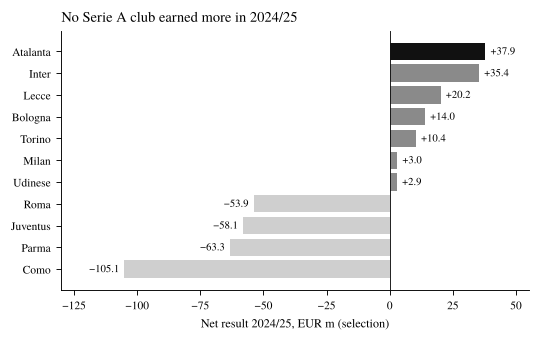

In [7]:
league = pd.read_csv(DATA / "serie_a_net_results_2024_25.csv").sort_values("net_result_2024_25_eur_m")
fig, ax = plt.subplots(figsize=(4.8, 3.0))
ax.barh(league["club"], league["net_result_2024_25_eur_m"],
        color=[INK if c == "Atalanta" else (GREY if v > 0 else LIGHT)
               for c, v in zip(league["club"], league["net_result_2024_25_eur_m"])])
ax.axvline(0, color=INK, lw=0.6)
ax.set_xlim(-130, 55)
for y, v in enumerate(league["net_result_2024_25_eur_m"]):
    ax.text(v + (2 if v > 0 else -2), y, f"{v:+.1f}", va="center", ha="left" if v > 0 else "right", fontsize=7)
ax.set_xlabel("Net result 2024/25, EUR m (selection)")
ax.set_title("No Serie A club earned more in 2024/25", loc="left", fontsize=9.5)
save(fig, "fig4_serie_a_2024_25")

## 5. Equity built from retained profits

Equity Dec 2019 to Jun 2025: 77.8 -> 248.2 (+170.4); profits in the period 153.0 = 90% of the growth
Financial debt / equity, June 2025: 0.22


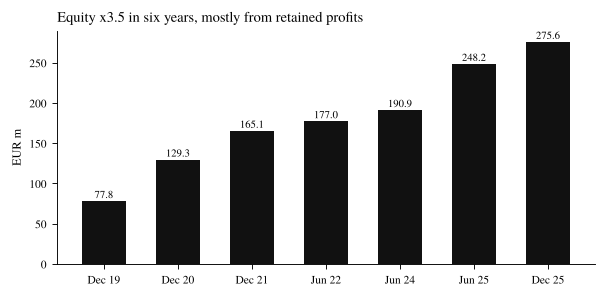

In [8]:
eq = pd.read_csv(DATA / "equity.csv", parse_dates=["date"])
profits_2020_jun25 = p.loc[p["period"].isin(["2020", "2021", "Jan-Jun 2022", "2022/23", "2023/24", "2024/25"]),
                           "net_profit_eur_m"].sum()
start = eq.loc[eq["date"] == "2019-12-31", "equity_eur_m"].item()
end = eq.loc[eq["date"] == "2025-06-30", "equity_eur_m"].item()
share = retained_earnings_share(start, end, profits_2020_jun25)
print(f"Equity Dec 2019 to Jun 2025: {start} -> {end} (+{end - start:.1f}); profits in the period {profits_2020_jun25:.1f} = {share:.0%} of the growth")
print(f"Financial debt / equity, June 2025: {54.8 / end:.2f}")

fig, ax = plt.subplots(figsize=(5.4, 2.6))
labels = eq["date"].dt.strftime("%b %y")
ax.bar(labels, eq["equity_eur_m"], color=INK, width=0.6)
for i, v in enumerate(eq["equity_eur_m"]):
    ax.text(i, v + 4, f"{v:.1f}", ha="center", fontsize=7)
ax.set_ylabel("EUR m")
ax.set_title(f"Equity x{eq['equity_eur_m'].iloc[-1] / start:.1f} in six years, mostly from retained profits", loc="left", fontsize=9.5)
save(fig, "fig5_equity")

## 6. The biggest sales in the club's history

Three of the top five came after Gasperini left (June 2025). Rows marked as estimates are press figures that are not in the accounts yet; they need checking against the 2025/26 and 2026/27 statements.

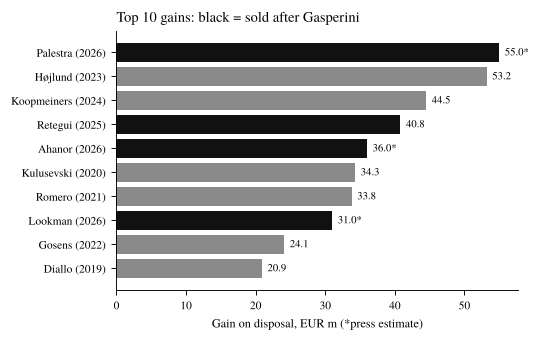

In [9]:
sales = pd.read_csv(DATA / "top_player_sales.csv").sort_values("gain_eur_m")
fig, ax = plt.subplots(figsize=(4.8, 3.0))
ax.barh([f"{n} ({y})" for n, y in zip(sales["player"], sales["year"])], sales["gain_eur_m"],
        color=[INK if g == "no" else GREY for g in sales["under_gasperini"]],
        hatch=None)
for yy, (v, est) in enumerate(zip(sales["gain_eur_m"], sales["estimate"])):
    ax.text(v + 0.8, yy, f"{v:.1f}" + ("*" if est != "no" else ""), va="center", fontsize=7)
ax.set_xlabel("Gain on disposal, EUR m (*press estimate)")
ax.set_title("Top 10 gains: black = sold after Gasperini", loc="left", fontsize=9.5)
save(fig, "fig6_top_sales")

## 7. The Pagliuca deal as a leveraged buyout

In 2022 the American investors did not buy the club directly. Their vehicle, Athena S.p.A., bought 55% of La Dea H, the Percassi holding that controls Atalanta, and paid for most of it with debt: a EUR 152.5m PIK toggle bond (8% cash or 8.75% paid in kind, due April 2027) and a EUR 23m vendor loan. That is a holding-company LBO. The club carries none of this debt, but the investors' equity sits behind it.

`src/pe_returns.py` rebuilds the deal with public figures and a few explicit assumptions:

* 100% of the club valued at EUR 450m at entry (press range 400 to 500m), so the 47% look-through stake cost about EUR 211m;
* interest always paid in kind at 8.75% (the worst case for the equity, and the natural one when the club pays no dividends);
* the vendor loan repaid at face value; the EUR 67m US share of the January 2025 capital increase counted as extra equity;
* exit value of the club = an EV/revenue multiple on 2024/25 revenue (EUR 320.8m). The 2022 deal was done at about 1.85x 2021 revenue.

In [10]:
from datetime import date
from src.pe_returns import (DealAssumptions, breakeven_club_value, holdco_debt, sensitivity,
                            sources_and_uses)

deal = DealAssumptions()
su = sources_and_uses(deal)
print(f"Entry LTV at the holding: {deal.entry_ltv:.0%}  |  equity cheque: EUR {deal.entry_equity:.1f}m")
su.round(2)

Entry LTV at the holding: 83%  |  equity cheque: EUR 36.0m


,side,item,eur_m,share_of_price
0,Uses,47% look-through stake in the club,211.5,1.00
1,Sources,PIK toggle bond (Athena S.p.A.),152.5,0.72
2,Sources,Vendor loan (Percassi family),23.0,0.11
3,Sources,Equity (US investors and Arctos),36.0,0.17


In [11]:
maturity = date(2027, 4, 30)
rev_2425 = p.loc[p["period"] == "2024/25", "revenue_eur_m"].item()
print(f"Holding debt at bond maturity (Apr 2027): EUR {holdco_debt(deal, maturity):.1f}m")
for label, m in [("debt repaid (equity worth zero)", 0.0), ("money back (MOIC 1.0x)", 1.0), ("MOIC 2.0x", 2.0)]:
    v = breakeven_club_value(deal, maturity, moic=m)
    print(f"Club value needed for {label:32s}: EUR {v:6.0f}m = {v / rev_2425:.2f}x 2024/25 revenue")

Holding debt at bond maturity (Apr 2027): EUR 256.5m
Club value needed for debt repaid (equity worth zero) : EUR    484m = 1.51x 2024/25 revenue
Club value needed for money back (MOIC 1.0x)          : EUR    679m = 2.12x 2024/25 revenue
Club value needed for MOIC 2.0x                       : EUR    873m = 2.72x 2024/25 revenue


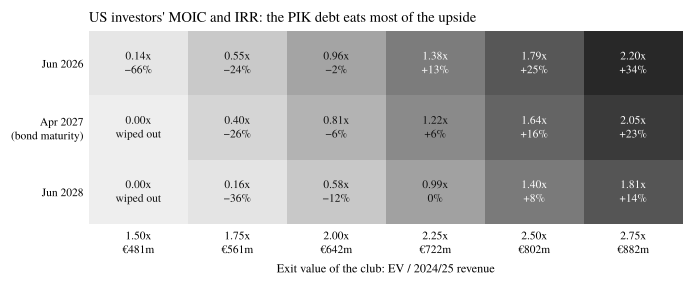

In [12]:
multiples = [1.50, 1.75, 2.00, 2.25, 2.50, 2.75]
exits = [date(2026, 6, 30), date(2027, 4, 30), date(2028, 6, 30)]
sens = sensitivity(deal, rev_2425, multiples, exits)
moic = sens.pivot(index="exit", columns="multiple", values="moic")
irr = sens.pivot(index="exit", columns="multiple", values="irr")

fig, ax = plt.subplots(figsize=(6.2, 2.5))
ax.imshow(moic.to_numpy(), cmap="Greys", vmin=-0.4, vmax=2.6, aspect="auto")
for i in range(moic.shape[0]):
    for j in range(moic.shape[1]):
        m, r = moic.iat[i, j], irr.iat[i, j]
        pct = round(r * 100)
        txt = f"{m:.2f}x\n" + ((f"{pct:+d}%" if pct else "0%") if m > 0 else "wiped out")
        ax.text(j, i, txt, ha="center", va="center", fontsize=7.5, color="white" if m > 1.3 else INK)
ax.set_xticks(range(len(multiples)), [f"{m:.2f}x\n€{m * rev_2425:.0f}m" for m in multiples])
ax.set_yticks(range(len(exits)), ["Jun 2026", "Apr 2027\n(bond maturity)", "Jun 2028"])
ax.set_xlabel("Exit value of the club: EV / 2024/25 revenue")
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("US investors' MOIC and IRR: the PIK debt eats most of the upside", loc="left", fontsize=9.5)
save(fig, "fig7_pe_returns_sensitivity")

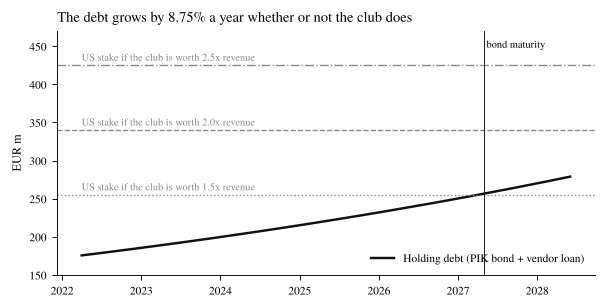

In [13]:
months = pd.date_range("2022-04-01", "2028-06-30", freq="MS")
debt_path = [holdco_debt(deal, d.date()) for d in months]

fig, ax = plt.subplots(figsize=(5.4, 2.7))
ax.plot(months, debt_path, color=INK, lw=1.6, label="Holding debt (PIK bond + vendor loan)")
for m, ls in [(1.5, ":"), (2.0, "--"), (2.5, "-.")]:
    ax.axhline(deal.stake_after_follow_on * m * rev_2425, color=GREY, lw=0.9, ls=ls)
    ax.text(months[0], deal.stake_after_follow_on * m * rev_2425 + 6,
            f"US stake if the club is worth {m:.1f}x revenue", fontsize=6.8, color=GREY)
ax.axvline(pd.Timestamp(maturity), color=INK, lw=0.6)
ax.text(pd.Timestamp(maturity), 448, " bond maturity", fontsize=6.8)
ax.set_ylim(150, 470)
ax.set_ylabel("EUR m")
ax.legend(frameon=False, loc="lower right")
ax.set_title("The debt grows by 8.75% a year whether or not the club does", loc="left", fontsize=9.5)
save(fig, "fig8_holdco_debt")

## 8. Exports for Power BI

Tidy CSVs in `outputs/`, ready to be loaded into a Power BI or Excel model.

In [14]:
out = ROOT / "outputs"; out.mkdir(exist_ok=True)
p.drop(columns="source").to_csv(out / "periods_with_shares.csv", index=False)
bridge.reset_index(names="step").to_csv(out / "profit_bridge.csv", index=False)
sorted(f.name for f in out.iterdir())

['periods_with_shares.csv', 'profit_bridge.csv']

## What I take from this

* Over 2016 to 2024/25 the club made EUR 230.5m of profit and EUR 534m of gains on disposals. Without the gains, most years would have closed at a loss.
* The model is a cycle: buy young, play them, sell at the right time, reinvest. It works, and it has kept working with a different coach.
* For the American investors the club is a good asset inside a heavily levered structure: with interest paid in kind, the club has to be worth well above the 2022 entry multiple by 2027 for the equity to make money.
* It is also concentrated on one engine. A season without European football and without a big sale is the scenario to watch (2022/23 came close: EUR 5.6m profit, held up by EUR 63.2m of gains).